In [35]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub

/kaggle/input/competitions/movie-recommendation-hackathon-2026/sample_submission.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/imdb_data.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_scores.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/links.csv


In [36]:
#load the datasets and explore
movies=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv')
sample_submission=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/sample_submission.csv')
imdb_data=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/imdb_data.csv')
genome_tags=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_tags.csv')
genome_scores=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_scores.csv')
train=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv')
test=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv')
tags=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv')
links=pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/links.csv')

for name,d in [
    ("movies",movies),
    ("sample_submission",sample_submission),
    ("imdb_data",imdb_data),
    ("genome_tags",genome_tags),
    ("genome_scores",genome_scores),
    ("train",train),
    ("test",test),
    ("tags",tags),
    ("links",links)]:
    rows, columns=d.shape
    print(f"{name}->{rows:,}rows*{columns:,}columns")
    print(movies.head())
    print(sample_submission.head())
    print(genome_tags.head())
    print(genome_scores.head())
    print(train.head())
    print(test.head())
    print(tags.head())
    print(links.head())


movies->62,423rows*3columns
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
       Id  rating
0  1_2011     1.0
1  1_4144     1.0
2  1_5767     1.0
3  1_6711     1.0
4  1_7318     1.0
   tagId           tag
0      1           007
1      2  007 (series)
2      3  18th century
3      4         1920s
4      5         1930s
   movieId  tagId  relevance
0        1      1    0.02875
1        1      2    0.02375
2        1      3    0.06250
3        1     

In [37]:
#checking if there are duplicates
print("Movies duplicates:", movies.duplicated().sum())
print("sample_submission duplicates:", sample_submission.duplicated().sum())
print("Tags duplicates:", tags.duplicated().sum())
print("Genome_scores duplicates:", genome_scores.duplicated().sum())
print("test duplicates:", test.duplicated().sum())
print("train duplicates:", train.duplicated().sum())
print("links duplicates:", links.duplicated().sum())
print("genome_tags duplicates:", genome_tags.duplicated().sum())
print("imdb_data duplicates:", imdb_data.duplicated().sum())

Movies duplicates: 0
sample_submission duplicates: 0
Tags duplicates: 0
Genome_scores duplicates: 0
test duplicates: 0
train duplicates: 0
links duplicates: 0
genome_tags duplicates: 0
imdb_data duplicates: 0


In [39]:
#check missing values
print("Movies missing values:\n", movies.isnull().sum())
print("\nsample_submission missing values:\n", sample_submission.isnull().sum())
print("\nTags missing values:\n", tags.isnull().sum())
print("\nGenome_scores missing values:\n", genome_scores.isnull().sum())
print("test missing values:\n", test.isnull().sum())
print("\ntrain missing values:\n", train.isnull().sum())
print("\nlinks missing values:\n", links.isnull().sum())
print("\ngenome_tags missing values:\n", genome_tags.isnull().sum())
print("\nimdb_data missing values:\n", imdb_data.isnull().sum())

Movies missing values:
 movieId    0
title      0
genres     0
dtype: int64

sample_submission missing values:
 Id        0
rating    0
dtype: int64

Tags missing values:
 userId        0
movieId       0
tag          16
timestamp     0
dtype: int64

Genome_scores missing values:
 movieId      0
tagId        0
relevance    0
dtype: int64
test missing values:
 userId     0
movieId    0
dtype: int64

train missing values:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

links missing values:
 movieId      0
imdbId       0
tmdbId     107
dtype: int64

genome_tags missing values:
 tagId    0
tag      0
dtype: int64

imdb_data missing values:
 movieId              0
title_cast       10068
director          9874
runtime          12089
budget           19372
plot_keywords    11078
dtype: int64


In [40]:
import pandas as pd, matplotlib.pyplot as plt, time
from scipy import sparse
from numba import njit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import Ridge
from sklearn.preprocessing import normalize

SEED = 42
rng = np.random.default_rng(SEED)         
#does the SAME user rate the SAME movie more than once?
print("train columns:", train.columns.tolist())
print("repeated (user, movie) pairs:", train.duplicated(["userId", "movieId"]).sum())

#keep only what we need, average any repeats, shrink the data types
train = train[["userId", "movieId", "rating"]]
if train.duplicated(["userId", "movieId"]).any():
    train = train.groupby(["userId", "movieId"], as_index=False)["rating"].mean()
train = train.astype({"userId": "int32", "movieId": "int32", "rating": "float32"})   # half the memory
test  = test[["userId", "movieId"]].astype({"userId": "int32", "movieId": "int32"})  # NEVER drop rows from test

#ratings must be valid
print("rating values:", np.sort(train["rating"].unique()).tolist())
assert train["rating"].between(0.5, 5.0).all(), "ratings outside 0.5-5 found"

#fix only the missing values we actually use
tags["tag"] = tags["tag"].fillna("").astype(str)
print("train", train.shape, "| test", test.shape)

train columns: ['userId', 'movieId', 'rating', 'timestamp']
repeated (user, movie) pairs: 0
rating values: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
train (10000038, 3) | test (5000019, 2)


ratings 10,000,038 | users 162,541 | movies 48,213 | matrix 99.87% empty
mean rating 3.533 | std 1.037


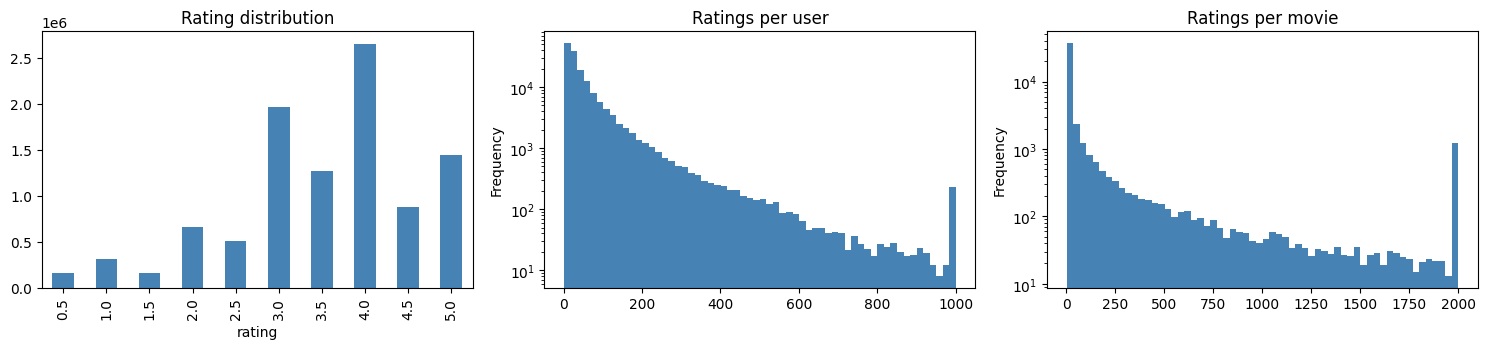

test rows: known user 100.0% | known movie 99.9% | both 99.9%


In [41]:
n_u, n_i = train.userId.nunique(), train.movieId.nunique()
print(f"ratings {len(train):,} | users {n_u:,} | movies {n_i:,} | matrix {100*(1 - len(train)/(n_u*n_i)):.2f}% empty")
print("mean rating", round(train.rating.mean(), 3), "| std", round(train.rating.std(), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
train.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Rating distribution")
train.groupby("userId").size().clip(upper=1000).plot.hist(bins=60, ax=ax[1], log=True, color="steelblue"); ax[1].set_title("Ratings per user")
train.groupby("movieId").size().clip(upper=2000).plot.hist(bins=60, ax=ax[2], log=True, color="steelblue"); ax[2].set_title("Ratings per movie")
plt.tight_layout(); plt.show()

known_u = test.userId.isin(train.userId).values
known_i = test.movieId.isin(train.movieId).values
print(f"test rows: known user {known_u.mean():.1%} | known movie {known_i.mean():.1%} | both {(known_u & known_i).mean():.1%}")

In [42]:
user_index = pd.Index(np.union1d(train.userId.unique(), test.userId.unique()))
item_index = pd.Index(np.union1d(np.union1d(movies.movieId.values, train.movieId.unique()), test.movieId.unique()))
n_users, n_items = len(user_index), len(item_index)

u_all = user_index.get_indexer(train.userId.values).astype(np.int64)
i_all = item_index.get_indexer(train.movieId.values).astype(np.int64)
r_all = train.rating.values.astype(np.float64)

is_val = rng.random(len(r_all)) < 0.10
u_tr, i_tr, r_tr = u_all[~is_val], i_all[~is_val], r_all[~is_val]
u_va, i_va, r_va = u_all[is_val],  i_all[is_val],  r_all[is_val]
VAL = (u_va, i_va, r_va)
cnt_u_tr = np.bincount(u_tr, minlength=n_users)     # train ratings per user
cnt_i_tr = np.bincount(i_tr, minlength=n_items)     # train ratings per movie

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def clip(p):    return np.clip(p, 0.5, 5.0)          # ratings live in [0.5, 5]
print(f"users {n_users:,} | movies {n_items:,} | train {len(r_tr):,} | validation {len(r_va):,}")

users 162,541 | movies 62,423 | train 9,000,817 | validation 999,221


In [43]:
def fit_biases(u, i, r, n_users, n_items, lam_i=10.0, lam_u=15.0, iters=10):
    mu = r.mean()
    cnt_u = np.bincount(u, minlength=n_users); cnt_i = np.bincount(i, minlength=n_items)
    bu = np.zeros(n_users); bi = np.zeros(n_items)
    for _ in range(iters):
        bi = np.bincount(i, weights=r - mu - bu[u], minlength=n_items) / (lam_i + cnt_i)
        bu = np.bincount(u, weights=r - mu - bi[i], minlength=n_users) / (lam_u + cnt_u)
    return mu, bu, bi

print("global mean RMSE:", round(rmse(r_va, np.full(len(r_va), r_tr.mean())), 4))
best = None
for lam_i, lam_u in [(2, 2), (10, 15), (25, 25), (50, 50)]:
    mu_b, bu_b, bi_b = fit_biases(u_tr, i_tr, r_tr, n_users, n_items, lam_i, lam_u)
    s = rmse(r_va, clip(mu_b + bu_b[u_va] + bi_b[i_va]))
    print(f"bias model lam=({lam_i},{lam_u}): RMSE {s:.4f}")
    if best is None or s < best[0]: best = (s, lam_i, lam_u)
RMSE_BIAS, BASE_LAM_I, BASE_LAM_U = best
mu_b, bu_b, bi_b = fit_biases(u_tr, i_tr, r_tr, n_users, n_items, BASE_LAM_I, BASE_LAM_U)
print("best baseline RMSE:", round(RMSE_BIAS, 4), "<- every later model must beat this")

global mean RMSE: 1.0604
bias model lam=(2,2): RMSE 0.8628
bias model lam=(10,15): RMSE 0.8652
bias model lam=(25,25): RMSE 0.8691
bias model lam=(50,50): RMSE 0.8775
best baseline RMSE: 0.8628 <- every later model must beat this


In [45]:
@njit(cache=True, fastmath=True)
def _sgd_epoch(u, i, r, order, mu, bu, bi, P, Q, lr, reg_b, reg_f):
    k = P.shape[1]
    for t in range(order.shape[0]):
        idx = order[t]; uu = u[idx]; ii = i[idx]
        dot = 0.0
        for f in range(k):
            dot += P[uu, f] * Q[ii, f]
        err = r[idx] - (mu + bu[uu] + bi[ii] + dot)          # how wrong were we?
        bu[uu] += lr * (err - reg_b * bu[uu])
        bi[ii] += lr * (err - reg_b * bi[ii])
        for f in range(k):
            pf = P[uu, f]; qf = Q[ii, f]
            P[uu, f] += lr * (err * qf - reg_f * pf)
            Q[ii, f] += lr * (err * pf - reg_f * qf)
def predict_mf(m, u, i, chunk=500_000):
    out = np.empty(len(u))
    for s in range(0, len(u), chunk):                        # chunks keep memory small
        uu, ii = u[s:s+chunk], i[s:s+chunk]
        out[s:s+chunk] = m["mu"] + m["bu"][uu] + m["bi"][ii] + np.einsum("ij,ij->i", m["P"][uu], m["Q"][ii])
    return out

def train_mf(u, i, r, k=32, epochs=20, lr=0.03, lr_decay=0.97, reg_b=0.02, reg_f=0.05,
             val=None, patience=3, min_epochs=12, init=0.1, seed=SEED, verbose=True):
    rs = np.random.RandomState(seed)
    mu, bu, bi = fit_biases(u, i, r, n_users, n_items, BASE_LAM_I, BASE_LAM_U)   # start from the baseline
    P = rs.normal(0, init, (n_users, k)); Q = rs.normal(0, init, (n_items, k))
    cnt_u, cnt_i = np.bincount(u, minlength=n_users), np.bincount(i, minlength=n_items)
    best, best_ep, best_score, bad, hist = None, epochs, np.inf, 0, []
    for ep in range(1, epochs + 1):
        _sgd_epoch(u, i, r, rs.permutation(len(r)), mu, bu, bi, P, Q, lr, reg_b, reg_f)
        lr *= lr_decay
        m = dict(mu=mu, bu=bu, bi=bi, P=P, Q=Q)
        if val is not None:
            score = rmse(val[2], clip(predict_mf(m, val[0], val[1]))); hist.append(score)
            if verbose: print(f"epoch {ep:>2}  val RMSE {score:.4f}")
            if score < best_score - 1e-5:
                best_score, best_ep, bad = score, ep, 0
                best = {key: (v.copy() if isinstance(v, np.ndarray) else v) for key, v in m.items()}
            else:
                bad += 1
                if bad >= patience and ep >= min_epochs: break      # early stopping
    model = best if val is not None else dict(mu=mu, bu=bu, bi=bi, P=P, Q=Q)
    # users/movies with NO training ratings never got updated: zero them so they fall back to the biases
    model["P"][cnt_u == 0] = 0; model["Q"][cnt_i == 0] = 0
    model["bu"][cnt_u == 0] = 0; model["bi"][cnt_i == 0] = 0
    return model, best_ep, (best_score if val is not None else None), hist 

In [46]:
TUNE_ROWS = 1_000_000
sub = rng.choice(len(r_tr), size=min(TUNE_ROWS, len(r_tr)), replace=False)
results = []
for k in [16, 32]:
    for reg in [0.04, 0.06, 0.10]:
        _, ep, score, _ = train_mf(u_tr[sub], i_tr[sub], r_tr[sub], k=k, reg_f=reg,
                                   epochs=50, val=VAL, verbose=False)
        results.append(dict(k=k, reg_f=reg, best_epoch=ep, val_rmse=round(score, 4)))
        print(results[-1])
tune = pd.DataFrame(results).sort_values("val_rmse")
BEST_K, BEST_REG = int(tune.iloc[0].k), float(tune.iloc[0].reg_f)
print("chosen: k =", BEST_K, " reg =", BEST_REG)

m_mf, BEST_EPOCHS, _, _ = train_mf(u_tr, i_tr, r_tr, k=BEST_K, reg_f=BEST_REG,
                                   epochs=60, val=VAL, verbose=False)
RMSE_MF = rmse(r_va, clip(predict_mf(m_mf, u_va, i_va)))
print(f"bias {RMSE_BIAS:.4f} -> matrix factorization {RMSE_MF:.4f}  (best epoch {BEST_EPOCHS})")

{'k': 16, 'reg_f': 0.04, 'best_epoch': 1, 'val_rmse': 0.9024}
{'k': 16, 'reg_f': 0.06, 'best_epoch': 1, 'val_rmse': 0.9023}
{'k': 16, 'reg_f': 0.1, 'best_epoch': 1, 'val_rmse': 0.9022}
{'k': 32, 'reg_f': 0.04, 'best_epoch': 1, 'val_rmse': 0.9028}
{'k': 32, 'reg_f': 0.06, 'best_epoch': 1, 'val_rmse': 0.9026}
{'k': 32, 'reg_f': 0.1, 'best_epoch': 1, 'val_rmse': 0.9024}
chosen: k = 16  reg = 0.1
bias 0.8628 -> matrix factorization 0.8194  (best epoch 60)


In [47]:
#genome_scores is "long" (one row per movie x tag) -> wide matrix G (one row per movie, one column per tag)
genome_ids, inv = np.unique(genome_scores["movieId"].values, return_inverse=True)
G = np.zeros((len(genome_ids), int(genome_scores["tagId"].max())), dtype=np.float32)
G[inv, genome_scores["tagId"].values - 1] = genome_scores["relevance"].values   # tagIds start at 1
del inv                                         # (optional) also `del genome_scores` to free ~400 MB of memory
tag_name = genome_tags.set_index("tagId")["tag"]
title_of = movies.set_index("movieId")["title"]

#one row of descriptive info per movie
meta = movies.set_index("movieId").reindex(item_index.values).join(imdb_data.set_index("movieId"), how="left")
for c in ["title", "genres", "title_cast", "director", "plot_keywords"]:
    meta[c] = meta[c].fillna("")
NOT_GENRES = {"(no genres listed)", "IMAX"}      # IMAX is a screen format, not a genre
meta["genres_clean"] = meta["genres"].apply(lambda s: "|".join(g for g in s.split("|") if g not in NOT_GENRES))
meta["title_clean"]  = meta["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

year = meta["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype(float)
year_z = ((year.fillna(year.median()) - year.median()) / year.std()).clip(-3, 3).values

# imdbId is roughly chronological (Spearman 0.96 with release year): z-score its rank, missing -> 0
imdb_rank = links.set_index("movieId")["imdbId"].reindex(item_index.values).rank(pct=True)
imdb_z = ((imdb_rank.fillna(0.5) - 0.5) / imdb_rank.std()).clip(-3, 3).values

# one text "document" per movie from the tags users wrote
tag_docs = (tags.groupby("movieId")["tag"].apply(lambda s: " ".join(s.str.lower()))
                .reindex(item_index.values).fillna(""))

def pipe_tokens(s): return [t for t in s.split("|") if t]     # "a|b|c" -> [a, b, c]
def top3(s):        return pipe_tokens(s)[:3]                 # only the 3 top-billed actors
WORDS = r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
spec = [   # (vectoriser, text, weight): the weight says how much each source matters
    (TfidfVectorizer(tokenizer=pipe_tokens, token_pattern=None, lowercase=False), meta["genres_clean"], 0.5),
    (TfidfVectorizer(token_pattern=WORDS, stop_words="english", min_df=3, sublinear_tf=True), meta["plot_keywords"], 0.6),
    (TfidfVectorizer(tokenizer=pipe_tokens, token_pattern=None, lowercase=False, min_df=2), meta["director"], 0.4),
    (TfidfVectorizer(tokenizer=top3, token_pattern=None, lowercase=False, min_df=2), meta["title_cast"], 0.4),
    (TfidfVectorizer(token_pattern=WORDS, stop_words="english", min_df=2), meta["title_clean"], 0.3),
    (TfidfVectorizer(token_pattern=WORDS, stop_words="english", min_df=5, sublinear_tf=True), tag_docs, 0.8),
]
M = sparse.hstack([w * v.fit_transform(txt) for v, txt, w in spec]).tocsr()

def zscore(A): return (A - A.mean(0)) / (A.std(0) + 1e-9)
# text block -> 48 dims
Cm = zscore(TruncatedSVD(48, random_state=SEED).fit_transform(M))    
# where each genome movie sits
gp = item_index.get_indexer(genome_ids)
svd_g = TruncatedSVD(32, random_state=SEED)
# genome -> 32 "themes"
Zg = zscore(svd_g.fit_transform(G))

# no genome -> 0 (neutral)
Cg = np.zeros((n_items, 32)); Cg[gp[gp >= 0]] = Zg[gp >= 0]
has_g = np.zeros(n_items);    has_g[gp[gp >= 0]] = 1.0
 
# one content row per movie
C = np.hstack([Cg, Cm, has_g[:, None], year_z[:, None], imdb_z[:, None]])  # one content row per movie
print("content matrix:", C.shape)

# the tag names make the genome themes readable
for c in range(1, 4):
    load = svd_g.components_[c]
    print(f"theme {c}: + {[tag_name[t + 1] for t in np.argsort(-load)[:5]]}  - {[tag_name[t + 1] for t in np.argsort(load)[:5]]}")

content matrix: (62423, 83)
theme 1: + ['predictable', 'action', 'silly fun', 'silly', 'big budget']  - ['intimate', 'golden palm', 'criterion', 'bleak', 'downbeat']
theme 2: + ['horror', 'creepy', 'violence', 'murder', 'splatter']  - ['feel-good', 'touching', 'sentimental', 'love story', 'heartwarming']
theme 3: + ['thriller', 'suspense', 'tense', 'corruption', 'crime']  - ['independent film', 'weird', 'relationships', 'melancholic', 'intimate']


In [48]:
MIN_WARM, ALPHA = 20, 10

def fit_content_map(m, cnt_i, alpha=ALPHA, min_warm=MIN_WARM):
    warm = np.where(cnt_i >= min_warm)[0]                  # movies with enough ratings to learn from
    Y = np.column_stack([m["bi"], m["Q"]])                 # targets: [bias, factors]
    wts = cnt_i[warm] / (cnt_i[warm] + 20.0)
    return Ridge(alpha=alpha).fit(C[warm], Y[warm], sample_weight=wts)

def blend(m, Yhat, cnt_i, lam_c):
    w = (cnt_i > 0).astype(float) if lam_c == 0 else np.where(cnt_i > 0, cnt_i / (cnt_i + lam_c), 0.0)
    out = dict(m)
    out["bi"] = w * m["bi"] + (1 - w) * Yhat[:, 0]
    out["Q"]  = w[:, None] * m["Q"] + (1 - w)[:, None] * Yhat[:, 1:]
    return out

reg_map = fit_content_map(m_mf, cnt_i_tr)
Yhat = reg_map.predict(C)                                  # content-only estimate for EVERY movie
rows = []
for lam_c in [0, 3, 10, 30, 100, 300]:
    p = clip(predict_mf(blend(m_mf, Yhat, cnt_i_tr, lam_c), u_va, i_va))
    rows.append((lam_c, round(rmse(r_va, p), 4)))
print(rows)
BEST_LAM_C = min(rows, key=lambda x: x[1])[0]
m_hybrid = blend(m_mf, Yhat, cnt_i_tr, BEST_LAM_C)
RMSE_HYB = rmse(r_va, clip(predict_mf(m_hybrid, u_va, i_va)))
print(f"matrix factorization {RMSE_MF:.4f} -> hybrid {RMSE_HYB:.4f}  (lambda_c = {BEST_LAM_C})")

[(0, 0.8193), (3, 0.8186), (10, 0.8186), (30, 0.8187), (100, 0.819), (300, 0.8196)]
matrix factorization 0.8194 -> hybrid 0.8186  (lambda_c = 3)


In [49]:
preds = {
    "bias model":   clip(mu_b + bu_b[u_va] + bi_b[i_va]),
    "MF":           clip(predict_mf(m_mf, u_va, i_va)),
    "MF + content": clip(predict_mf(m_hybrid, u_va, i_va)),
}
bucket = pd.cut(cnt_i_tr[i_va], bins=[-1, 0, 4, 19, 99, np.inf], labels=["0", "1-4", "5-19", "20-99", "100+"])
table = []
for lab in bucket.categories:
    mk = (bucket == lab)
    if mk.sum():
        table.append({"movie_ratings": lab, "n": int(mk.sum()),
                      **{name: round(rmse(r_va[mk], p[mk]), 3) for name, p in preds.items()}})
print(pd.DataFrame(table).set_index("movie_ratings"))

                    n  bias model     MF  MF + content
movie_ratings                                         
0                1386       1.007  1.023         0.964
1-4              4658       0.973  1.035         0.951
5-19             9474       0.907  0.899         0.887
20-99           29501       0.880  0.843         0.841
100+           954202       0.861  0.816         0.816


In [50]:
m_full, _, _, _ = train_mf(u_all, i_all, r_all, k=BEST_K, reg_f=BEST_REG,
                           epochs=BEST_EPOCHS, val=None, verbose=False)
cnt_i_full = np.bincount(i_all, minlength=n_items)
reg_full = fit_content_map(m_full, cnt_i_full)
m_final = blend(m_full, reg_full.predict(C), cnt_i_full, BEST_LAM_C)

u_te = user_index.get_indexer(test.userId.values).astype(np.int64)
i_te = item_index.get_indexer(test.movieId.values).astype(np.int64)
pred_te = clip(predict_mf(m_final, u_te, i_te))
print(pd.Series(pred_te).describe().round(3))

# verify the sample's Id really is "userId_movieId" in the same order (spot-check)
chk = rng.choice(len(test), 100_000, replace=False)
expect = test.userId.iloc[chk].astype(str).values + "_" + test.movieId.iloc[chk].astype(str).values
assert len(sample_submission) == len(test) and (sample_submission.Id.iloc[chk].values == expect).all()

submission = pd.DataFrame({"Id": sample_submission["Id"].values, "rating": pred_te})
submission.to_csv("/kaggle/working/submission.csv", index=False, float_format="%.4f")
print("saved", submission.shape)

count    5000019.000
mean           3.535
std            0.651
min            0.500
25%            3.154
50%            3.604
75%            3.989
max            5.000
dtype: float64
saved (5000019, 2)
